# BS49903 · DS/AI for Biology
## Week 3 Practice Notebook — Convolution, Regression

Covers Week 3-1 and
Week 3-2 (kernels, correlation vs convolution, linear regression).

In [2]:
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

np.set_printoptions(precision=3, suppress=True)
DATA = "data/"

---
# Part 1 · pandas and 1D biological data

### 1.1 Load a table

A numpy array holds one dtype and has no column names. Real biological tables are mixed:
species (text), mass (float), sex (text). pandas adds labels, mixed dtypes and missing values.

In [3]:
df = pd.read_csv(DATA + "penguins.csv")

print("shape:", df.shape)
print("columns:", list(df.columns))
df.head()

shape: (344, 7)
columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### 1.2 Inspect before you compute

`info()` and `isna()` are the two commands that catch most data problems.

In [4]:
print(df.dtypes, "\n")          # text columns show as 'object' (pandas 2) or 'str' (pandas 3)
print(df.isna().sum())           # missing values per column

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object 

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [5]:
df.describe().round(1)           # NaN is ignored, so check the count row

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


`sex` has 11 missing values and the four measurement columns have 2.

### 1.3 Selecting columns

One name gives a **Series**; a *list* of names gives a **DataFrame**.

In [6]:
print(type(df["body_mass_g"]))        # Series
print(type(df[["body_mass_g"]]))      # DataFrame  <- note the double brackets

print()
print(df["body_mass_g"].head(3))

<class 'pandas.Series'>
<class 'pandas.DataFrame'>

0    3750.0
1    3800.0
2    3250.0
Name: body_mass_g, dtype: float64


### 1.4 Filtering rows

A comparison gives a boolean array; indexing with it keeps the `True` rows.
Combine conditions with `&  |  ~`, and put each condition in its own parentheses.

In [7]:
a = np.array([1, 2, 3, 4, 5])
print(a >= 3)
print(a[a >= 3])

[False False  True  True  True]
[3 4 5]


In [8]:
heavy = df[(df["species"] == "Gentoo") & (df["body_mass_g"] > 5500)]
print(heavy.shape)
heavy[["species", "sex", "body_mass_g"]].head(3)

(28, 7)


,species,sex,body_mass_g
221,Gentoo,MALE,5700.0
223,Gentoo,MALE,5700.0
231,Gentoo,MALE,5550.0


### 1.5 `.loc` (labels) vs `.iloc` (positions)

`.loc` slices by label and **includes** the end. `.iloc` slices by position and **excludes** it.

In [10]:
print(df.loc[2:4, "species":"bill_depth_mm"])      # rows 2,3,4 — end INCLUDED
print()
print(df.iloc[2:4, 0:3])                            # rows 2,3  — end EXCLUDED

  species     island  bill_length_mm  bill_depth_mm
2  Adelie  Torgersen            40.3           18.0
3  Adelie  Torgersen             NaN            NaN
4  Adelie  Torgersen            36.7           19.3

  species     island  bill_length_mm
2  Adelie  Torgersen            40.3
3  Adelie  Torgersen             NaN


---
# Part 2 · Summary statistics

### 2.1 One signal, and many signals

Load the BOLD data as an **N × T** matrix: one row per subject, one column per timepoint.

In [12]:
fmri = pd.read_csv(DATA + "fmri_bold.csv")
wide = (fmri.query("region == 'parietal' and event == 'stim'")
            .pivot_table(index="subject", columns="timepoint", values="signal"))
X = wide.values                       # N subjects x T timepoints

print("X shape:", X.shape, " = (N subjects, T timepoints)")

X shape: (14, 19)  = (N subjects, T timepoints)


### 2.2 `axis` decides what you average over

`axis=0` goes down the rows (across subjects), `axis=1` goes across the columns (over time).

In [13]:
mean_x = X.mean(axis=0)               # one value per TIMEPOINT, averaged over subjects
print("mean over subjects:", mean_x.shape, mean_x[:5])

mean_t = X.mean(axis=1)               # one value per SUBJECT, averaged over time
print("mean over time    :", mean_t.shape, mean_t[:5])

mean over subjects: (19,) [-0.025 -0.04  -0.02   0.061  0.177]
mean over time    : (14,) [ 0.001  0.043  0.043 -0.002  0.014]


The same thing written as a loop, to show there is no magic in `axis=0`:

In [14]:
N, T = X.shape
sum_x = np.zeros(T)
for i in range(N):
    sum_x = sum_x + X[i, :]
loop_mean = sum_x / N

print("loop == numpy ?", np.allclose(loop_mean, X.mean(axis=0)))

loop == numpy ? True


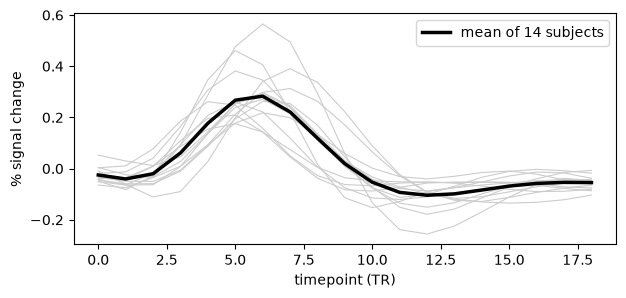

In [15]:
plt.figure(figsize=(7, 3))
plt.plot(X.T, color="0.8", lw=0.8)                       # every subject
plt.plot(mean_x, color="k", lw=2.5, label="mean of 14 subjects")
plt.xlabel("timepoint (TR)"); plt.ylabel("% signal change"); plt.legend(); plt.show()

### 2.3 numpy `std()` vs pandas `std()`

They disagree by default. numpy divides by N (population SD); pandas divides by N−1 (sample SD).

In [16]:
x = X[:, 5]                           # all subjects at one timepoint

print("np.std(x)         ", np.std(x))            # ddof=0
print("np.std(x, ddof=1) ", np.std(x, ddof=1))    # ddof=1
print("pd.Series(x).std()", pd.Series(x).std())   # ddof=1 by default
print()
print("ratio             ", pd.Series(x).std() / np.std(x))
print("sqrt(N/(N-1))     ", np.sqrt(len(x) / (len(x) - 1)))

np.std(x)          0.09579361483934258
np.std(x, ddof=1)  0.09940973215622316
pd.Series(x).std() 0.09940973215622316

ratio              1.0377490433255414
sqrt(N/(N-1))      1.0377490433255416


### 2.4 SD, SEM and the coefficient of variation

- **SD** — how variable the individuals are
- **SEM** = SD/√N — how precisely we know the *mean*; it shrinks with more subjects
- **CV** = SD/mean — variability *relative* to the mean, so it has no units

In [17]:
sd  = x.std(ddof=1)
sem = sd / np.sqrt(len(x))
cv  = sd / x.mean()
print(f"N = {len(x)}   mean = {x.mean():.4f}   SD = {sd:.4f}   SEM = {sem:.4f}   CV = {cv:.3f}")

N = 14   mean = 0.2672   SD = 0.0994   SEM = 0.0266   CV = 0.372


In [18]:
# CV lets you compare variability across completely different scales
for name, mean, s in [("elephant mass (kg)", 4000, 400), ("mouse mass (g)", 25, 2.5)]:
    print(f"{name:>20}:  mean {mean:>6}   SD {s:>5}   CV {s/mean:.2f}")

  elephant mass (kg):  mean   4000   SD   400   CV 0.10
      mouse mass (g):  mean     25   SD   2.5   CV 0.10


Same CV, wildly different SDs. CV says "both vary by about 10% of their typical size".

---
# Part 3 · The sliding window

### 3.1 The pattern

Take `w` consecutive values, compute one number, step forward by one, repeat.
The output has **N − w + 1** values, because the window must fit inside the data.

In [19]:
x = np.array([4, 8, 6, 2, 9, 5, 7, 3], dtype=float)
w = 3

out = []
for i in range(len(x) - w + 1):       # stop early so the last window still fits
    window = x[i:i+w]
    out.append(window.mean())

print("input ", x)
print("output", np.round(out, 2))
print("length", len(x), "->", len(out), " = N - w + 1")

input  [4. 8. 6. 2. 9. 5. 7. 3.]
output [6.   5.33 5.67 5.33 7.   5.  ]
length 8 -> 6  = N - w + 1


### 3.2 Change the function inside the loop, get a different tool

In [20]:
for name, func in [("mean", np.mean), ("max", np.max), ("std", lambda v: v.std(ddof=1))]:
    vals = [func(x[i:i+w]) for i in range(len(x) - w + 1)]
    print(f"{name:>5}:", np.round(vals, 2))

 mean: [6.   5.33 5.67 5.33 7.   5.  ]
  max: [8. 8. 9. 9. 9. 7.]
  std: [2.   3.06 3.51 3.51 2.   2.  ]


### 3.3 A sliding window with step 3: finding a codon

A codon is three bases read **in frame**. Stepping by 3 instead of 1 is the whole difference
between a string search and a biological question.

In [21]:
gene_seq = "GACAACTCATGGATGATATCA"
target   = "TGG"

codon_number = 0
for i in range(0, len(gene_seq) - 2, 3):       # i = 0, 3, 6, 9, ...
    codon = gene_seq[i:i+3]
    codon_number += 1
    if codon == target:
        print("found at codon", codon_number, " position", i)

found at codon 4  position 9


Now search for the start codon `ATG` in the same sequence, with step 1 and with step 3:

In [22]:
hits = [i for i in range(len(gene_seq) - 2) if gene_seq[i:i+3] == "ATG"]   # step 1
print("step 1, any position :", hits)
print("step 3, in frame     :", [i for i in hits if i % 3 == 0])
print()
print("offset  8:", gene_seq[:8],  "|", gene_seq[8:11],  "| not in frame (8 is not a multiple of 3)")
print("offset 12:", gene_seq[:12], "|", gene_seq[12:15], "| in frame -> codon 5")

step 1, any position : [8, 12]
step 3, in frame     : [12]

offset  8: GACAACTC | ATG | not in frame (8 is not a multiple of 3)
offset 12: GACAACTCATGG | ATG | in frame -> codon 5


`ATG` occurs twice as a *string*, but only one of them is an actual codon. The other
straddles two codons and codes for nothing. The step size is the whole biology.

### 3.4 Downsampling

Two ways to halve the sampling rate. Subsampling just keeps every other value;
block averaging averages pairs.

In [23]:
xd = np.arange(12).astype(float)

sub = xd[::2]                                   # subsampling / nearest neighbor

blk = []
for i in range(0, 12, 2):
    blk.append((xd[i] + xd[i+1]) / 2)           # block averaging

print("original      ", xd)
print("subsampled    ", sub)
print("block averaged", np.array(blk))

original       [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]
subsampled     [ 0.  2.  4.  6.  8. 10.]
block averaged [ 0.5  2.5  4.5  6.5  8.5 10.5]


On a straight line the two methods look almost the same. On a noisy signal they don't.
Downsample by 4 so the difference is easy to see:

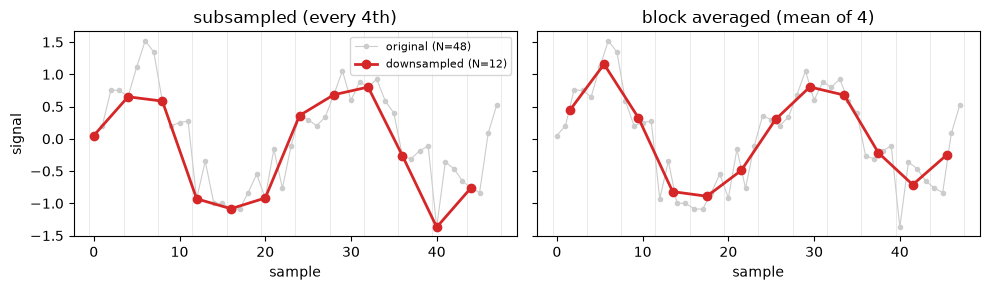

In [24]:
rng = np.random.default_rng(0)
t  = np.arange(48)
xs = np.sin(2 * np.pi * t / 24) + rng.normal(0, 0.4, len(t))   # slow wave + noise
f  = 4                                                          # downsampling factor

t_sub, x_sub = t[::f], xs[::f]                                  # keep every 4th sample
t_blk = t.reshape(-1, f).mean(axis=1)                           # centre of each block
x_blk = xs.reshape(-1, f).mean(axis=1)                          # average of each block

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, tt, xx, title in [(axes[0], t_sub, x_sub, "subsampled (every 4th)"),
                          (axes[1], t_blk, x_blk, "block averaged (mean of 4)")]:
    ax.plot(t, xs, "o-", color="0.8", ms=3, lw=0.8, label=f"original (N={len(t)})")
    ax.plot(tt, xx, "o-", color="C3", lw=2, label=f"downsampled (N={len(xx)})")
    for edge in range(0, len(t) + 1, f):
        ax.axvline(edge - 0.5, color="0.9", lw=0.6, zorder=0)    # block boundaries
    ax.set_title(title); ax.set_xlabel("sample")
axes[0].set_ylabel("signal"); axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

Subsampling keeps the noise of whichever sample it happens to land on. Block averaging
smooths each block first, so the slow wave survives. It is a sliding window with step = w.

---
# Part 4 · Kernels: correlation and convolution

### 4.1 Window vs kernel

A **window** is which samples you look at — any operation is allowed (`min`, `max`, `==`).
A **kernel** is a list of **weights** you multiply the samples by before summing.

### 4.2 Two ways to slide a kernel

$$(x \star h)_t = \sum_k h_k\, x_{t+k} \qquad\qquad (x * h)_t = \sum_k h_k\, x_{t-k}$$

Correlation uses $t+k$, convolution uses $t-k$. Before running the cell: what will each return?

In [25]:
signal_ = np.array([1, 2, 3, 4, 5])
kernel  = np.array([1, 2, 3])

print("correlation:", np.correlate(signal_, kernel))
print("convolution:", np.convolve(signal_, kernel, mode="valid"))

correlation: [14 20 26]
convolution: [10 16 22]


For the **first** output value:

- correlation lines the kernel up as written: `1*1 + 2*2 + 3*3 = 14`
- convolution lines it up **reversed**:      `3*1 + 2*2 + 1*3 = 10`

So correlation is the same as convolution with a flipped kernel:

In [26]:
print(np.correlate(signal_, kernel))
print(np.convolve(signal_, kernel[::-1], mode="valid"))

[14 20 26]
[14 20 26]


### 4.3 Convolution is commutative, correlation is not

In [27]:
print("convolution  x*h :", np.convolve(signal_, kernel))
print("convolution  h*x :", np.convolve(kernel, signal_))
print()
print("correlation  x*h :", np.correlate(signal_, kernel, mode="full"))
print("correlation  h*x :", np.correlate(kernel, signal_, mode="full"), " <- reversed!")

convolution  x*h : [ 1  4 10 16 22 22 15]
convolution  h*x : [ 1  4 10 16 22 22 15]

correlation  x*h : [ 3  8 14 20 26 14  5]
correlation  h*x : [ 5 14 26 20 14  8  3]  <- reversed!


Swapping the arguments of a correlation reverses the output. Convolution does not care,
because the two indices always add up to `t`.

### 4.4 Why convolution flips: the kernel is indexed by age

`h_k` is the response **k steps after** an impulse, so its index is an *age*, not a time.
At output time `t`, the input of age `k` is the one that arrived at `t − k`.
Written the other way round — each input spreading forward — there is no flip at all:

In [30]:
h = np.array([0.7, 0.2, 0.1])          # what one impulse leaves behind
imp = np.zeros(8); imp[2] = 1          # a single impulse at t = 2

spread = np.zeros(8 + len(h))
for t in np.flatnonzero(imp):          # for each INPUT ...
    for k in range(len(h)):
        spread[t + k] += h[k]          # ... lay down a copy of h.  PLUS, no flip

print("spread forward :", spread[:8])
print("np.convolve    :", np.convolve(imp, h)[:8])

spread forward : [0.  0.  0.7 0.2 0.1 0.  0.  0. ]
np.convolve    : [0.  0.  0.7 0.2 0.1 0.  0.  0. ]


Convolving with an impulse returns the kernel itself — that is why `h` is called the
**impulse response**, and why convolution is described as *memory*: the output now is the
pile-up of everything that already happened. One spike → one calcium transient.

### 4.5 Kernel = [1/w, 1/w, 1/w] is the moving average

In [31]:
w = 20
box = np.ones(w) / w
print("kernel:", box[:5], "...  sum =", round(box.sum(), 6))

mov_avg_kernel = np.convolve(lfp, box, mode="valid")

# the same thing as last week's loop
mov_avg_loop = [lfp[k:k+w].mean() for k in range(len(lfp) - w + 1)]
print("loop == convolution ?", np.allclose(mov_avg_loop, mov_avg_kernel))

kernel: [0.05 0.05 0.05 0.05 0.05] ...  sum = 1.0
loop == convolution ? True


### 4.6 A Gaussian kernel smooths better

The box has a hard edge; the Gaussian falls off smoothly and removes high-frequency noise
more cleanly. Both must sum to 1 so the signal keeps its level.

gaussian sum: 1.0   symmetric: True


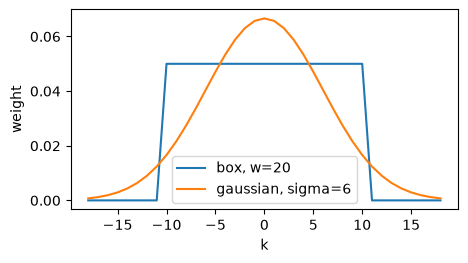

In [32]:
k = np.arange(-18, 19)
gauss = np.exp(-k**2 / (2 * 6.0**2))
gauss = gauss / gauss.sum()                  # normalize so the weights sum to 1

print("gaussian sum:", gauss.sum().round(6), "  symmetric:", np.allclose(gauss, gauss[::-1]))

plt.figure(figsize=(5, 2.6))
plt.plot(k, np.where(abs(k) <= w//2, 1/w, 0), label=f"box, w={w}")
plt.plot(k, gauss, label="gaussian, sigma=6")
plt.xlabel("k"); plt.ylabel("weight"); plt.legend(); plt.show()

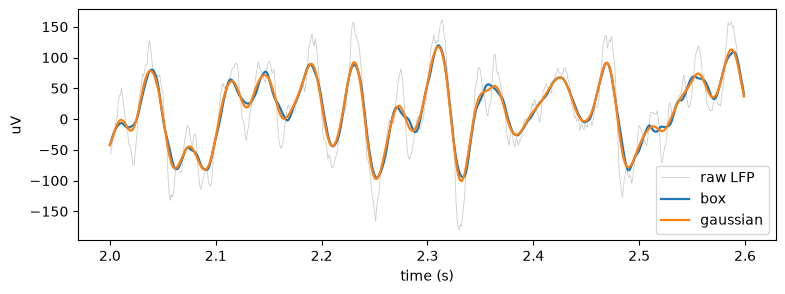

In [33]:
fs = 1000
t = np.arange(len(lfp)) / fs
seg = slice(2000, 2600)

sm_box   = np.convolve(lfp, box,   mode="same")
sm_gauss = np.convolve(lfp, gauss, mode="same")

plt.figure(figsize=(9, 3))
plt.plot(t[seg], lfp[seg], color="0.8", lw=0.6, label="raw LFP")
plt.plot(t[seg], sm_box[seg], lw=1.6, label="box")
plt.plot(t[seg], sm_gauss[seg], lw=1.6, label="gaussian")
plt.xlabel("time (s)"); plt.ylabel("uV"); plt.legend(); plt.show()

Larger window → smoother, but local features are lost. Smaller window → keeps more noise.
Any feature shorter than the window gets averaged away.

Note also: for a **symmetric** kernel, correlation and convolution give the same answer.

In [34]:
import scipy.signal as sps
print("max difference:", np.abs(np.convolve(lfp, gauss, "same")
                                - sps.correlate(lfp, gauss, "same")).max())

max difference: 0.0


---
# Part 5 · Linear regression

### 5.1 The model

Given N data points with features $x$ and an output $y$, find the $\beta$ that best
explains the data:

$$\hat y = \beta_0 + \beta_1 x$$

Regression is a **predictor**: given a new data point, what value is it likely to have?

In [35]:
peng = df.dropna()
xf = peng["flipper_length_mm"].values
ym = peng["body_mass_g"].values

lr = LinearRegression().fit(xf[:, None], ym)

print(f"intercept b0 = {lr.intercept_:.1f} g")
print(f"slope     b1 = {lr.coef_[0]:.2f} g per mm")
print(f"R2           = {lr.score(xf[:, None], ym):.3f}")

intercept b0 = -5872.1 g
slope     b1 = 50.15 g per mm
R2           = 0.762


In [36]:
# predict: a new penguin with a 205 mm flipper
print("one new penguin :", lr.predict([[205]]).round(1), "g")
print("three at once   :", lr.predict([[190], [205], [220]]).round(1))

# predict needs a 2-D array — one row per sample
try:
    lr.predict([205])
except ValueError as e:
    print("\nValueError:", str(e)[:70], "...")

one new penguin : [4409.3] g
three at once   : [3657.  4409.3 5161.6]

ValueError: Expected 2D array, got 1D array instead:
array=[205].
Reshape your dat ...


### 5.2 Fitting it by hand

$$L = \lVert \mathbf{y} - \mathbf{X}\mathbf{b}\rVert^2
= \sum_i (y_i - \mathbf{x}_i \cdot \mathbf{b})^2
\qquad\Longrightarrow\qquad
\hat{\mathbf{b}} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$$

`X` is n × p (a column of ones gives the intercept), `b` is p × 1, `y` is n × 1.

In [40]:
Xd = np.column_stack([np.ones_like(xf), xf])          # n x 2
b  = np.linalg.solve(Xd.T @ Xd, Xd.T @ ym)            

print("by hand :", b.round(2))
print("sklearn :", np.array([lr.intercept_, lr.coef_[0]]).round(2))

by hand : [-5872.09    50.15]
sklearn : [-5872.09    50.15]


### 5.3 Residuals and R²

$$\text{residual} = y - \hat y \qquad\qquad
R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}$$

Residuals should look like noise with no structure if the model is good.

R2 by hand: 0.762    sklearn: 0.762


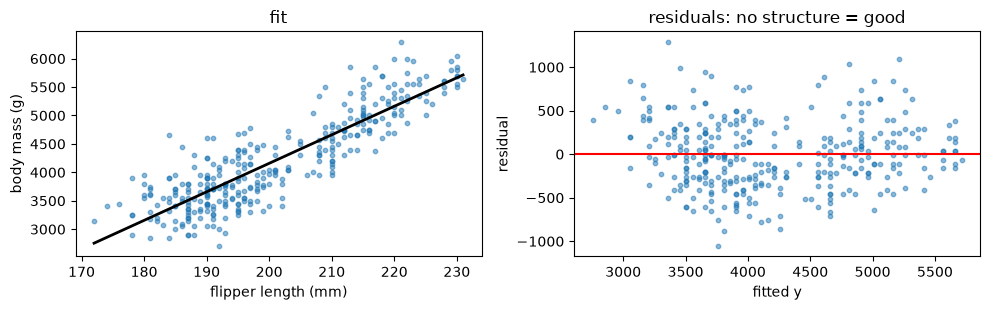

In [38]:
yhat = lr.predict(xf[:, None])
res  = ym - yhat

r2_by_hand = 1 - (res**2).sum() / ((ym - ym.mean())**2).sum()
print("R2 by hand:", round(r2_by_hand, 3), "   sklearn:", round(lr.score(xf[:, None], ym), 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].scatter(xf, ym, s=10, alpha=0.5)
xs = np.array([[xf.min()], [xf.max()]])
ax[0].plot(xs, lr.predict(xs), color="k", lw=2)
ax[0].set(xlabel="flipper length (mm)", ylabel="body mass (g)", title="fit")
ax[1].scatter(yhat, res, s=10, alpha=0.5); ax[1].axhline(0, color="r")
ax[1].set(xlabel="fitted y", ylabel="residual", title="residuals: no structure = good")
plt.tight_layout(); plt.show()

R² = 1 is perfect, R² = 0 means the model does no better than predicting the mean.

But a high R² is not automatically good news, and a small R² can still be highly significant —
the p-value mostly reflects your sample size.

### 5.4 What does "linear" mean?

$$\hat y = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3$$

Is this linear? **Yes.** $x, x^2, x^3$ are just known numbers. "Linear" means linear in $\beta$ —
so a polynomial fit is still linear regression, with extra columns in `X`.

In [39]:
Xpoly = np.column_stack([xf, xf**2, xf**3])        # three features, still linear in beta
poly = LinearRegression().fit(Xpoly, ym)

print("coefficients:", poly.coef_.round(4))
print("R2 linear    :", round(lr.score(xf[:, None], ym), 3))
print("R2 cubic     :", round(poly.score(Xpoly, ym), 3), " <- more columns can only increase R2")

coefficients: [-0.001 -0.283  0.001]
R2 linear    : 0.762
R2 cubic     : 0.777  <- more columns can only increase R2


That last line is the warning for next week: adding columns can only ever raise the training
R², so training performance can never tell you whether a model is actually better.